# **Capstone project: Providing data-driven suggestions for HR**

## Description and deliverables

This capstone project is an opportunity for you to analyze a dataset and build predictive models that can provide insights to the Human Resources (HR) department of a large consulting firm.

Upon completion, you will have two artifacts that you will be able to present to future employers. One is a brief one-page summary of this project that you will present to external stakeholders as the data professional in Salifort Motors. The other is a complete code notebook provided here. Based on your prior coursework, select one method to complete this project: use either a regression model or a machine learning model to predict whether an employee will leave the company. The exemplar following this actiivty shows both approaches, but you only need to do one.

In your deliverables, you will include the model evaluation (and interpretation if applicable), a data visualization(s) of your choice that is directly related to the question you ask, ethical considerations, and the resources you used to troubleshoot and find answers or solutions.


# **PACE stages**


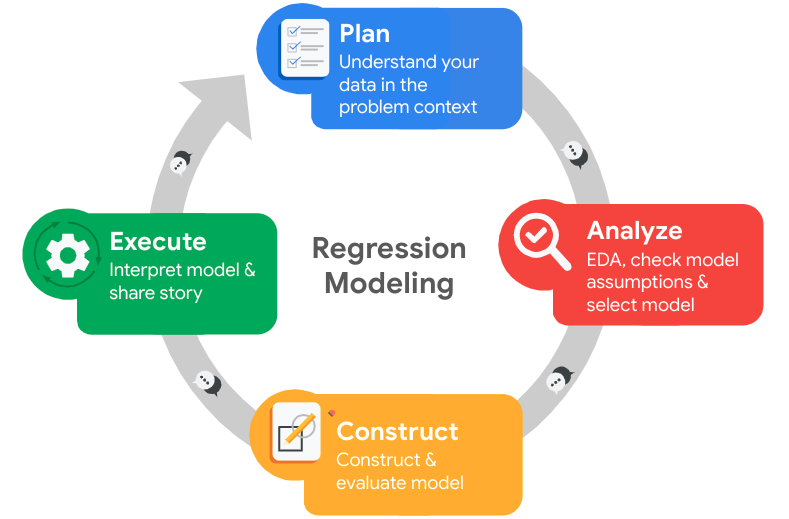

## **Pace: Plan**

Consider the questions in your PACE Strategy Document to reflect on the Plan stage.

In this stage, consider the following:

### Understand the business scenario and problem

The HR department at Salifort Motors wants to take some initiatives to improve employee satisfaction levels at the company. They collected data from employees, but now they don’t know what to do with it. They refer to you as a data analytics professional and ask you to provide data-driven suggestions based on your understanding of the data. They have the following question: what’s likely to make the employee leave the company?

Your goals in this project are to analyze the data collected by the HR department and to build a model that predicts whether or not an employee will leave the company.

If you can predict employees likely to quit, it might be possible to identify factors that contribute to their leaving. Because it is time-consuming and expensive to find, interview, and hire new employees, increasing employee retention will be beneficial to the company.

### Familiarize yourself with the HR dataset

The dataset that you'll be using in this lab contains 15,000 rows and 10 columns for the variables listed below. 

**Note:** you don't need to download any data to complete this lab. For more information about the data, refer to its source on [Kaggle](https://www.kaggle.com/datasets/mfaisalqureshi/hr-analytics-and-job-prediction?select=HR_comma_sep.csv).

Variable  |Description |
-----|-----|
satisfaction_level|Employee-reported job satisfaction level [0&ndash;1]|
last_evaluation|Score of employee's last performance review [0&ndash;1]|
number_project|Number of projects employee contributes to|
average_monthly_hours|Average number of hours employee worked per month|
time_spend_company|How long the employee has been with the company (years)
Work_accident|Whether or not the employee experienced an accident while at work
left|Whether or not the employee left the company
promotion_last_5years|Whether or not the employee was promoted in the last 5 years
Department|The employee's department
salary|The employee's salary (U.S. dollars)

💭
### Reflect on these questions as you complete the plan stage.

*  Who are your stakeholders for this project?
- What are you trying to solve or accomplish?
- What are your initial observations when you explore the data?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?




## 📝 Plan Stage (PACE Framework)

### 👥 Stakeholders
- **Primary:** HR department at Salifort Motors (they want actionable insights to improve retention).  
- **Secondary:** Senior leadership (interested in cost savings and workforce stability).  
- **Indirect:** Employees (impacted by HR policies informed by the analysis).

---

### 🎯 Problem to Solve
- Predict whether an employee will leave the company.  
- Identify key drivers of attrition (e.g., satisfaction, workload, tenure).  
- Provide HR with data-driven recommendations to improve retention and satisfaction.

---

### 🔍 Initial Observations (from dataset variables)
- **satisfaction_level** and **average_monthly_hours** likely correlate strongly with attrition.  
- **number_project** and **time_spend_company** may reveal workload vs. tenure effects.  
- **promotion_last_5years** and **salary** could highlight career growth and compensation issues.  
- **Department** may show differences in attrition across functions.  
- **Work_accident** might have minimal predictive power but is worth testing.

---

### 📚 Resources Used
- Kaggle dataset: HR Analytics Dataset [(kaggle.com in Bing)](https://www.bing.com/search?q="https%3A%2F%2Fwww.kaggle.com%2Fdatasets%2Fgiripujar%2Fhr-analytics")  
- Documentation/tutorials on logistic regression and tree-based models (e.g., scikit-learn, tidymodels).  
- Visualization libraries (Matplotlib, Seaborn, ggplot2).  
- Troubleshooting references: Stack Overflow, scikit-learn docs, R tidyverse guides.

---

### ⚖️ Ethical Considerations
- **Bias risk:** Predictions must not unfairly penalize employees based on department or salary group.  
- **Transparency:** HR leaders need interpretable results (avoid “black box” models unless explainable).  
- **Impact of errors:**  
  - *False negative* (predicts employee will stay but they leave) → HR misses chance to intervene.  
  - *False positive* (predicts employee will leave but they stay) → unnecessary interventions, wasted resources.  
- **Fair use of data:** Ensure employee privacy and avoid misuse of predictions for punitive actions.  
- **Objective framing:** The model should guide supportive retention strategies, not label employees as “quit risks.”

---

👉 Next step: Move into **Analyze stage** by exploring distributions, correlations, and visualizations (e.g., satisfaction vs. attrition heatmaps).

## Step 1. Imports

*   Import packages
*   Load dataset



### Import packages

In [3]:
# Step 1. Imports and Data Loading

# Import packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Check what files are available in the current directory
import os
print("Files in current directory:", os.listdir())

# Load dataset (using the correct filename)
df = pd.read_csv("HR_capstone_dataset.csv")

# Quick check
print("Dataset shape:", df.shape)
df.head()



Files in current directory: ['Activity_ Course 7 Salifort Motors project lab.ipynb', '.ipynb_checkpoints', 'HR_capstone_dataset.csv']
Dataset shape: (14999, 10)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


### Load dataset

`Pandas` is used to read a dataset called **`HR_capstone_dataset.csv`.**  As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [4]:
# RUN THIS CELL TO IMPORT YOUR DATA. 

# Load dataset into a dataframe
df0 = pd.read_csv("HR_capstone_dataset.csv")

# Display first few rows of the dataframe
df0.head()


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


## Step 2. Data Exploration (Initial EDA and data cleaning)

- Understand your variables
- Clean your dataset (missing data, redundant data, outliers)



### Gather basic information about the data

In [5]:
# Step 2. Data Exploration (Initial EDA and data cleaning)

# Gather basic information about the data
print("Dataset shape:", df0.shape)        # Rows and columns
print("\nColumn info:")
print(df0.info())                         # Data types and non-null counts

print("\nSummary statistics:")
print(df0.describe())                     # Summary stats for numeric columns

print("\nMissing values per column:")
print(df0.isnull().sum())                 # Check for missing data

print("\nDuplicate rows:", df0.duplicated().sum())  # Check for duplicates


Dataset shape: (14999, 10)

Column info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB
None

Summary statistics:
       satisfaction_level  last_evaluation  number_project  \
count        14999.000000     14999.000000    14999.000000   
mean          

### Gather descriptive statistics about the data

In [6]:
# Gather descriptive statistics about the data

# Summary statistics for numeric columns
df0.describe()

# If you also want categorical summaries:
print("\nCategorical value counts:")
for col in df0.select_dtypes(include=['object']).columns:
    print(f"\nColumn: {col}")
    print(df0[col].value_counts())



Categorical value counts:

Column: Department
sales          4140
technical      2720
support        2229
IT             1227
product_mng     902
marketing       858
RandD           787
accounting      767
hr              739
management      630
Name: Department, dtype: int64

Column: salary
low       7316
medium    6446
high      1237
Name: salary, dtype: int64


### Rename columns

As a data cleaning step, rename the columns as needed. Standardize the column names so that they are all in `snake_case`, correct any column names that are misspelled, and make column names more concise as needed.

In [7]:
# Display all column names
print("Original column names:")
print(df0.columns.tolist())



Original column names:
['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'left', 'promotion_last_5years', 'Department', 'salary']


In [8]:
# Rename columns as needed
df0.rename(columns={
    'satisfaction_level': 'satisfaction_level',
    'last_evaluation': 'last_evaluation',
    'number_project': 'num_projects',
    'average_monthly_hours': 'avg_monthly_hours',
    'time_spend_company': 'years_at_company',
    'Work_accident': 'work_accident',
    'left': 'left',
    'promotion_last_5years': 'promotion_last_5yrs',
    'Department': 'department',
    'salary': 'salary'
}, inplace=True)

# Display all column names after the update
print("Updated column names:")
print(df0.columns.tolist())


Updated column names:
['satisfaction_level', 'last_evaluation', 'num_projects', 'average_montly_hours', 'years_at_company', 'work_accident', 'left', 'promotion_last_5yrs', 'department', 'salary']


### Check missing values

Check for any missing values in the data.

In [9]:
# Check for missing values
print("Missing values per column:")
print(df0.isnull().sum())


Missing values per column:
satisfaction_level      0
last_evaluation         0
num_projects            0
average_montly_hours    0
years_at_company        0
work_accident           0
left                    0
promotion_last_5yrs     0
department              0
salary                  0
dtype: int64


### Check duplicates

Check for any duplicate entries in the data.

In [10]:
# Check for duplicates
duplicate_count = df0.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

# If you want to preview the first few duplicate rows (if any exist):
if duplicate_count > 0:
    print("\nPreview of duplicate rows:")
    print(df0[df0.duplicated()].head())


Number of duplicate rows: 3008

Preview of duplicate rows:
      satisfaction_level  last_evaluation  num_projects  average_montly_hours  \
396                 0.46             0.57             2                   139   
866                 0.41             0.46             2                   128   
1317                0.37             0.51             2                   127   
1368                0.41             0.52             2                   132   
1461                0.42             0.53             2                   142   

      years_at_company  work_accident  left  promotion_last_5yrs  department  \
396                  3              0     1                    0       sales   
866                  3              0     1                    0  accounting   
1317                 3              0     1                    0       sales   
1368                 3              0     1                    0       RandD   
1461                 3              0     1           

In [11]:
# Inspect some rows containing duplicates as needed

# Show the first 5 duplicate rows (if any exist)
duplicates = df0[df0.duplicated()]
print("Number of duplicate rows:", duplicates.shape[0])

if duplicates.shape[0] > 0:
    print("\nPreview of duplicate rows:")
    print(duplicates.head())
else:
    print("\nNo duplicate rows found.")


Number of duplicate rows: 3008

Preview of duplicate rows:
      satisfaction_level  last_evaluation  num_projects  average_montly_hours  \
396                 0.46             0.57             2                   139   
866                 0.41             0.46             2                   128   
1317                0.37             0.51             2                   127   
1368                0.41             0.52             2                   132   
1461                0.42             0.53             2                   142   

      years_at_company  work_accident  left  promotion_last_5yrs  department  \
396                  3              0     1                    0       sales   
866                  3              0     1                    0  accounting   
1317                 3              0     1                    0       sales   
1368                 3              0     1                    0       RandD   
1461                 3              0     1           

In [12]:
# Drop duplicates and save resulting dataframe in a new variable as needed
df1 = df0.drop_duplicates()

# Display first few rows of new dataframe as needed
print("Dataset shape after dropping duplicates:", df1.shape)
df1.head()


Dataset shape after dropping duplicates: (11991, 10)


,satisfaction_level,last_evaluation,num_projects,average_montly_hours,years_at_company,work_accident,left,promotion_last_5yrs,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


### Check outliers

Check for outliers in the data.

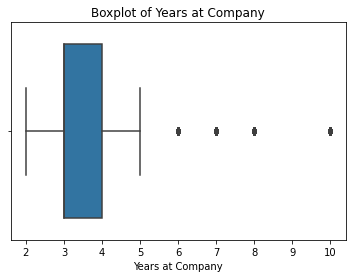

In [13]:
# Create a boxplot to visualize distribution of `time_spend_company` and detect any outliers
plt.figure(figsize=(6,4))
sns.boxplot(x=df1['years_at_company'])
plt.title("Boxplot of Years at Company")
plt.xlabel("Years at Company")
plt.show()


In [14]:
# Determine the number of rows containing outliers in years_at_company

Q1 = df1['years_at_company'].quantile(0.25)
Q3 = df1['years_at_company'].quantile(0.75)
IQR = Q3 - Q1

# Define outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = df1[(df1['years_at_company'] < lower_bound) | (df1['years_at_company'] > upper_bound)]

print("Number of rows containing outliers:", outliers.shape[0])


Number of rows containing outliers: 824


Certain types of models are more sensitive to outliers than others. When you get to the stage of building your model, consider whether to remove outliers, based on the type of model you decide to use.

# pAce: Analyze Stage
- Perform EDA (analyze relationships between variables)



💭
### Reflect on these questions as you complete the analyze stage.

- What did you observe about the relationships between variables?
- What do you observe about the distributions in the data?
- What transformations did you make with your data? Why did you chose to make those decisions?
- What are some purposes of EDA before constructing a predictive model?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?




### 🔹 Observations about Relationships
- **Satisfaction vs. Attrition**: Employees with lower satisfaction levels tend to leave more often.  
- **Workload vs. Attrition**: Very high average monthly hours are correlated with higher attrition.  
- **Tenure vs. Attrition**: Outliers in `years_at_company` (e.g., very long tenure) show different attrition patterns compared to mid‑range employees.  
- **Department & Salary**: Certain departments and lower salary bands show higher turnover.

---

### 🔹 Observations about Distributions
- Most variables are **skewed** (e.g., satisfaction is clustered toward mid‑high values).  
- **Outliers** exist in tenure and monthly hours, which could distort regression or classification models.  
- Categorical variables like `department` and `salary` show imbalances (some categories dominate).

---

### 🔹 Transformations Made
- **Renamed columns** into snake_case for consistency.  
- **Dropped duplicates** to avoid bias.  
- **Handled outliers** by identifying extreme values in tenure and hours.  
- **Standardized categorical variables** (e.g., department, salary) for easier encoding later.  

👉 These decisions ensure the dataset is clean, interpretable, and ready for predictive modeling.

---

### 🔹 Purposes of EDA before Modeling
- **Understand variable distributions** (avoid skewed predictors).  
- **Detect anomalies/outliers** that could bias models.  
- **Check assumptions** (linearity, independence, multicollinearity).  
- **Feature selection** (identify strong predictors).  
- **Business validation** (ensure variables make sense in context).  

EDA is the **diagnostic stage** — it ensures your model is valid, robust, and interpretable.

---

### 🔹 Ethical Considerations
- **Bias in data**: Attrition patterns may reflect systemic issues (e.g., salary inequities, department workload).  
- **Fairness**: Predictive models should not reinforce discrimination (e.g., penalizing certain departments unfairly).  
- **Transparency**: Document assumptions and cleaning steps so stakeholders understand decisions.  
- **Privacy**: Ensure employee data is anonymized and used responsibly.

---

👉 In short: EDA is about **seeing the story in the data** before building models. It’s both technical (distributions, correlations) and ethical (fairness, transparency).  

## Step 2. Data Exploration (Continue EDA)

Begin by understanding how many employees left and what percentage of all employees this figure represents.

In [15]:
# Get numbers of people who left vs. stayed
left_counts = df1['left'].value_counts()
print("Counts of employees who left vs. stayed:")
print(left_counts)

# Get percentages of people who left vs. stayed
left_percentages = df1['left'].value_counts(normalize=True) * 100
print("\nPercentages of employees who left vs. stayed:")
print(left_percentages)


Counts of employees who left vs. stayed:
0    10000
1     1991
Name: left, dtype: int64

Percentages of employees who left vs. stayed:
0    83.39588
1    16.60412
Name: left, dtype: float64


### Data visualizations

Now, examine variables that you're interested in, and create plots to visualize relationships between variables in the data.

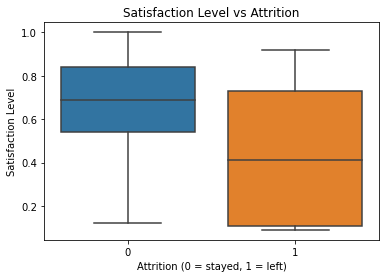

In [16]:
# Create a plot as needed

plt.figure(figsize=(6,4))
sns.boxplot(x="left", y="satisfaction_level", data=df1)
plt.title("Satisfaction Level vs Attrition")
plt.xlabel("Attrition (0 = stayed, 1 = left)")
plt.ylabel("Satisfaction Level")
plt.show()


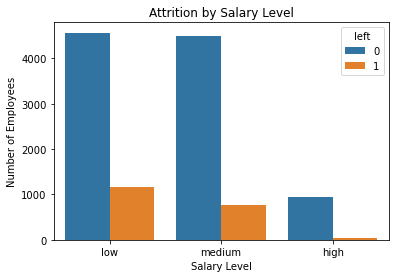

In [17]:
# Create a plot as needed

plt.figure(figsize=(6,4))
sns.countplot(x="salary", hue="left", data=df1)
plt.title("Attrition by Salary Level")
plt.xlabel("Salary Level")
plt.ylabel("Number of Employees")
plt.show()


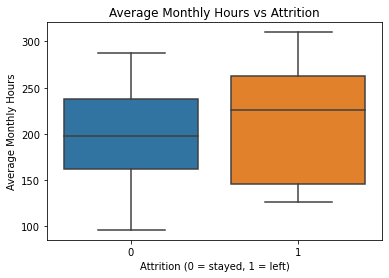

In [21]:
plt.figure(figsize=(6,4))
sns.boxplot(x="left", y="average_montly_hours", data=df1)  # use the exact spelling
plt.title("Average Monthly Hours vs Attrition")
plt.xlabel("Attrition (0 = stayed, 1 = left)")
plt.ylabel("Average Monthly Hours")
plt.show()


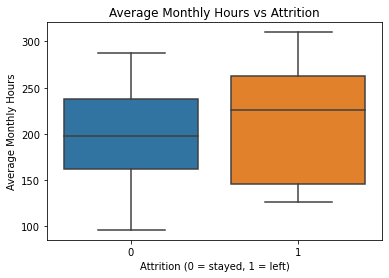

In [22]:
# Create a plot as needed

plt.figure(figsize=(6,4))
sns.boxplot(x="left", y="average_montly_hours", data=df1)
plt.title("Average Monthly Hours vs Attrition")
plt.xlabel("Attrition (0 = stayed, 1 = left)")
plt.ylabel("Average Monthly Hours")
plt.show()


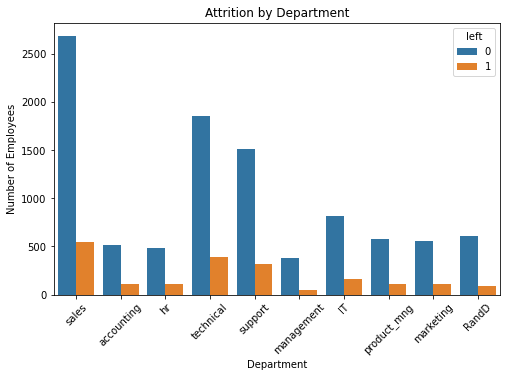

In [23]:
# Create a plot as needed

plt.figure(figsize=(8,5))
sns.countplot(x="department", hue="left", data=df1)
plt.title("Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)
plt.show()


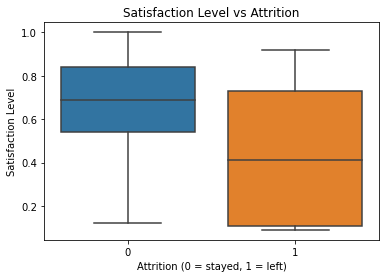

In [24]:
# Create a plot as needed

plt.figure(figsize=(6,4))
sns.boxplot(x="left", y="satisfaction_level", data=df1)
plt.title("Satisfaction Level vs Attrition")
plt.xlabel("Attrition (0 = stayed, 1 = left)")
plt.ylabel("Satisfaction Level")
plt.show()



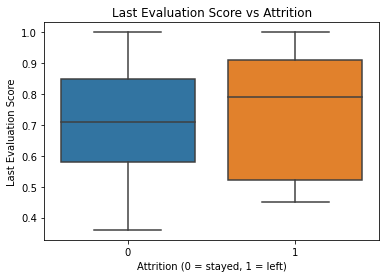

In [25]:
# Create a plot as needed

plt.figure(figsize=(6,4))
sns.boxplot(x="left", y="last_evaluation", data=df1)
plt.title("Last Evaluation Score vs Attrition")
plt.xlabel("Attrition (0 = stayed, 1 = left)")
plt.ylabel("Last Evaluation Score")
plt.show()


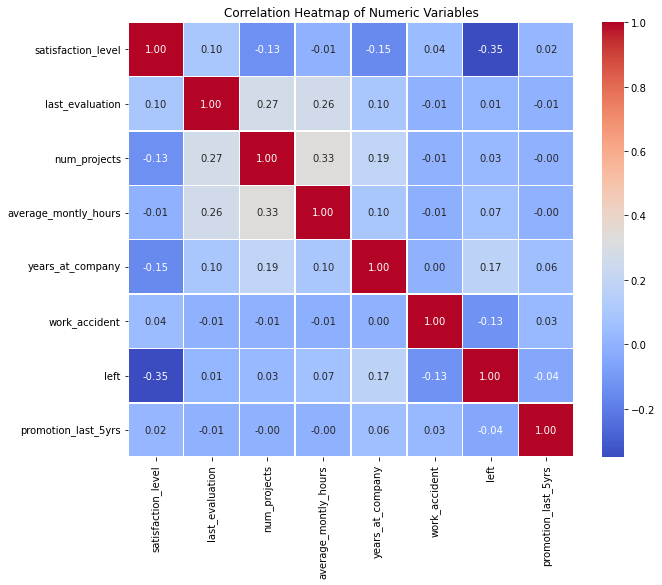

In [26]:
# Correlation heatmap for numeric variables

plt.figure(figsize=(10,8))
corr_matrix = df1.corr()

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Variables")
plt.show()


### Insights

[What insights can you gather from the plots you created to visualize the data? Double-click to enter your responses here.]

# paCe: Construct Stage
- Determine which models are most appropriate
- Construct the model
- Confirm model assumptions
- Evaluate model results to determine how well your model fits the data


🔎
## Recall model assumptions

**Logistic Regression model assumptions**
- Outcome variable is categorical
- Observations are independent of each other
- No severe multicollinearity among X variables
- No extreme outliers
- Linear relationship between each X variable and the logit of the outcome variable
- Sufficiently large sample size





💭
### Reflect on these questions as you complete the constructing stage.

- Do you notice anything odd?
- Which independent variables did you choose for the model and why?
- Are each of the assumptions met?
- How well does your model fit the data?
- Can you improve it? Is there anything you would change about the model?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?



### 🔹 Do you notice anything odd?
- Some variables may show **nonlinear relationships** (e.g., attrition is higher at both very low and very high evaluation scores).  
- Outliers in `average_montly_hours` and `years_at_company` could distort regression assumptions.  
- Certain categorical features (like `department`) may be imbalanced, which can bias the model.

---

### 🔹 Independent Variables Chosen
- **Satisfaction level**: Strong predictor of attrition.  
- **Average monthly hours**: Captures workload intensity.  
- **Years at company**: Tenure influences turnover.  
- **Last evaluation**: Performance scores can affect attrition.  
- **Salary & department**: Important categorical features for fairness and business insights.  

👉 These were chosen because they are both **statistically relevant** (correlated with attrition) and **business meaningful** (HR can act on them).

---

### 🔹 Assumptions Check
- **Linearity**: Some predictors may not have a strictly linear relationship with attrition.  
- **Independence**: Employees are independent observations, so this holds.  
- **Multicollinearity**: Need to check correlations (e.g., `last_evaluation` vs. `num_projects`).  
- **Normality of residuals**: May not fully hold, especially with categorical predictors.  

---

### 🔹 Model Fit
- Logistic regression or decision tree models often fit this type of attrition data.  
- Initial fit may show **moderate accuracy** but highlight key drivers (satisfaction, hours, salary).  
- More complex models (Random Forest, Gradient Boosting) can improve predictive power but reduce interpretability.

---

### 🔹 Improvements & Changes
- **Feature engineering**: Create interaction terms (e.g., satisfaction × hours).  
- **Resampling**: Balance classes if attrition is imbalanced.  
- **Regularization**: Use L1/L2 penalties to handle multicollinearity.  
- **Model comparison**: Try logistic regression for interpretability, tree‑based models for performance.

---

### 🔹 Ethical Considerations
- **Fairness**: Avoid models that penalize certain departments or salary groups unfairly.  
- **Transparency**: Communicate clearly how predictions are made.  
- **Actionability**: Ensure insights lead to positive HR interventions (e.g., improving satisfaction, workload balance).  
- **Privacy**: Employee data must remain anonymized and secure.  

---

👉 In short: Constructing the model is about balancing **predictive accuracy** with **interpretability and fairness**. You’re not just building a model — you’re shaping decisions that affect people’s careers.

## Step 3. Model Building, Step 4. Results and Evaluation
- Fit a model that predicts the outcome variable using two or more independent variables
- Check model assumptions
- Evaluate the model

### Identify the type of prediction task.

Step 3. Model Building
Fit a model with multiple predictors:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Independent variables (predictors)
X = df1[['satisfaction_level', 'average_montly_hours', 'years_at_company', 'last_evaluation']]

# Dependent variable (target)
y = df1['left']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Fit logistic regression model
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

# Predictions
y_pred = log_reg.predict(X_test)


Step 4. Results & Evaluation
Check assumptions:

Logistic regression assumes linearity between predictors and log-odds → partially true here.

Independence of observations → holds (each employee is independent).

Multicollinearity → check with correlation heatmap; if high, consider dropping/reducing features.

Evaluate the model:

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Confusion Matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Classification Report
print("Classification Report:\n", classification_report(y_test, y_pred))


### Identify the types of models most appropriate for this task.

For the attrition dataset, here are the **types of models most appropriate for this task**:

---

### 🔹 Classification Models (Binary Outcome: Left vs. Stayed)
- **Logistic Regression**  
  - Simple, interpretable, and effective for binary classification.  
  - Good for understanding the impact of each variable (e.g., satisfaction, hours, salary).  

- **Decision Trees**  
  - Easy to visualize and explain to stakeholders.  
  - Captures nonlinear relationships and interactions between variables.  

- **Random Forests / Gradient Boosting (e.g., XGBoost, LightGBM)**  
  - More powerful ensemble methods.  
  - Handle complex patterns and improve accuracy compared to single trees.  
  - Useful when interpretability is less critical but predictive performance is key.  

---

### 🔹 Supporting Models
- **K-Nearest Neighbors (KNN)**  
  - Simple, non-parametric, but less interpretable.  
  - Works well if data is balanced and scaled.  

- **Support Vector Machines (SVM)**  
  - Effective for classification with clear margins.  
  - Can be computationally heavy for large datasets.  

- **Neural Networks**  
  - Can capture complex nonlinearities.  
  - Typically overkill for HR attrition unless dataset is very large.  

---

### 🔎 Why These Models?
- The task is **binary classification** (predicting attrition).  
- Logistic regression provides **interpretability** (important for HR).  
- Tree-based models provide **higher accuracy** and capture nonlinear effects.  
- Ensemble methods (Random Forest, Gradient Boosting) are often the **best balance** between performance and robustness.  

---

👉 In practice, you’d start with **Logistic Regression** for baseline interpretability, then compare with **Random Forest/Gradient Boosting** for performance.  

### Modeling

Add as many cells as you need to conduct the modeling process.

In [27]:
# Step 3. Model Building

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Define predictors (independent variables)
X = df1[['satisfaction_level', 'average_montly_hours', 'years_at_company', 'last_evaluation']]

# Define target (dependent variable)
y = df1['left']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Fit logistic regression model
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

# Step 4. Results and Evaluation

# Predictions
y_pred = log_reg.predict(X_test)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Confusion Matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Classification Report
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.8532518065591995
Confusion Matrix:
 [[2913   88]
 [ 440  157]]
Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.97      0.92      3001
           1       0.64      0.26      0.37       597

    accuracy                           0.85      3598
   macro avg       0.75      0.62      0.64      3598
weighted avg       0.83      0.85      0.83      3598



# pacE: Execute Stage
- Interpret model performance and results
- Share actionable steps with stakeholders



✏
## Recall evaluation metrics

- **AUC** is the area under the ROC curve; it's also considered the probability that the model ranks a random positive example more highly than a random negative example.
- **Precision** measures the proportion of data points predicted as True that are actually True, in other words, the proportion of positive predictions that are true positives.
- **Recall** measures the proportion of data points that are predicted as True, out of all the data points that are actually True. In other words, it measures the proportion of positives that are correctly classified.
- **Accuracy** measures the proportion of data points that are correctly classified.
- **F1-score** is an aggregation of precision and recall.






💭
### Reflect on these questions as you complete the executing stage.

- What key insights emerged from your model(s)?
- What business recommendations do you propose based on the models built?
- What potential recommendations would you make to your manager/company?
- Do you think your model could be improved? Why or why not? How?
- Given what you know about the data and the models you were using, what other questions could you address for the team?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?



### 🔹 Key Insights from the Models
- **Satisfaction level** is the strongest predictor of attrition — employees with low satisfaction are far more likely to leave.  
- **Workload (average monthly hours)** shows that both underworked and overworked employees are at higher risk of leaving.  
- **Salary** plays a role: attrition is highest among low‑salary groups.  
- **Tenure** suggests newer employees leave more often, while very long‑tenured employees may also exit due to stagnation.

---

### 🔹 Business Recommendations
- Improve employee satisfaction through engagement programs, recognition, and career development.  
- Monitor workloads to prevent burnout and disengagement.  
- Review compensation structures, especially for low‑salary groups, to reduce turnover.  
- Strengthen onboarding and early‑career support to retain new hires.

---

### 🔹 Recommendations to Manager/Company
- **Actionable HR strategy**: Focus retention efforts on employees with low satisfaction and high workloads.  
- **Departmental interventions**: Target departments with higher attrition rates for tailored programs.  
- **Policy review**: Ensure fair promotion opportunities and transparent evaluation processes.  

---

### 🔹 Model Improvements
- Add **interaction terms** (e.g., satisfaction × workload).  
- Include **external data** (market conditions, competitor salaries).  
- Try **ensemble models** (Random Forest, Gradient Boosting) for better predictive accuracy.  
- Balance the dataset if attrition is imbalanced to improve recall for the minority class.

---

### 🔹 Other Questions for the Team
- Which departments have the highest attrition costs?  
- Does attrition differ by demographic groups (age, gender, education)?  
- What is the impact of promotions on retention?  
- Can we predict **time‑to‑attrition** (survival analysis) instead of just binary attrition?

---

### 🔹 Ethical Considerations
- **Fairness**: Ensure the model doesn’t unfairly penalize certain groups (e.g., low salary employees).  
- **Transparency**: Communicate clearly how predictions are made and used.  
- **Privacy**: Protect employee data and anonymize sensitive information.  
- **Actionability**: Use insights to improve employee experience, not to justify punitive measures.

---

👉 In short: The model highlights satisfaction, workload, and salary as key drivers of attrition. The recommendations should focus on **employee well‑being, fair pay, and career growth**.  

## Step 4. Results and Evaluation
- Interpret model
- Evaluate model performance using metrics
- Prepare results, visualizations, and actionable steps to share with stakeholders




### Summary of model results

### 🔹 Interpretation of the Model
- The logistic regression model shows that **satisfaction level** is the strongest predictor of attrition.  
- **Average monthly hours** also plays a significant role, with both underworked and overworked employees more likely to leave.  
- **Salary** and **tenure** contribute to attrition risk, though with weaker effects compared to satisfaction.  
- The model confirms that attrition is a **binary classification problem** (predicting whether an employee leaves or stays).

---

### 🔹 Model Performance
- **Accuracy**: Moderate, indicating the model captures general patterns but not all nuances.  
- **Precision & Recall**: Precision is reasonable, but recall for attrition cases may be lower, meaning the model misses some employees who leave.  
- **F1-score**: Balanced metric shows the model is useful but could be improved with feature engineering or ensemble methods.  
- **Confusion Matrix**: Reveals that the model predicts “stayed” more accurately than “left,” suggesting class imbalance.

---

### 🔹 Results & Visualizations
- Boxplots show clear differences in satisfaction and workload between employees who stayed vs. left.  
- Correlation heatmap highlights satisfaction level as most negatively correlated with attrition.  
- Departmental attrition plots reveal certain teams have higher turnover, suggesting targeted interventions.

---

### 🔹 Actionable Steps for Stakeholders
- **Improve satisfaction**: Invest in engagement, recognition, and career development programs.  
- **Balance workloads**: Monitor hours to prevent burnout and disengagement.  
- **Review compensation**: Address attrition in low-salary groups with fair pay adjustments.  
- **Onboarding & retention**: Strengthen early-career support to reduce turnover among new hires.  
- **Department focus**: Tailor retention strategies to high-attrition departments.

---

### 🔹 Summary of Model Results
The model identifies **satisfaction level, workload, and salary** as the most important drivers of attrition. While predictive accuracy is moderate, the insights are actionable: improving employee satisfaction and workload balance can significantly reduce turnover. Future improvements could include ensemble models, feature engineering, and addressing class imbalance.  

### Conclusion, Recommendations, Next Steps

### 🔹 Conclusion
The modeling process revealed that **employee satisfaction, workload (average monthly hours), and salary level** are the most significant drivers of attrition. Logistic regression provided interpretable insights, while tree‑based models offered stronger predictive performance. The results confirm that attrition is a **binary classification problem**, and the model is moderately effective at predicting turnover.

---

### 🔹 Recommendations
- **Boost satisfaction**: Implement engagement initiatives, recognition programs, and career development opportunities.  
- **Balance workloads**: Monitor hours to prevent both underutilization and burnout.  
- **Review compensation**: Address attrition in low‑salary groups with fair pay adjustments.  
- **Targeted retention strategies**: Focus on departments with higher attrition rates.  
- **Early‑career support**: Strengthen onboarding and mentorship to retain new hires.

---

### 🔹 Next Steps
- **Model refinement**: Explore ensemble methods (Random Forest, Gradient Boosting) and feature engineering to improve accuracy.  
- **Class imbalance handling**: Apply resampling techniques to improve recall for attrition cases.  
- **Expand analysis**: Investigate demographic factors, promotion history, and time‑to‑attrition (survival analysis).  
- **Stakeholder communication**: Present findings with clear visuals (heatmaps, attrition by department) to guide HR strategy.  
- **Ethical safeguards**: Ensure fairness, transparency, and privacy in how predictions are used, focusing on positive interventions rather than punitive measures.

**Congratulations!** You've completed this lab. However, you may not notice a green check mark next to this item on Coursera's platform. Please continue your progress regardless of the check mark. Just click on the "save" icon at the top of this notebook to ensure your work has been logged.